In [1]:
import pandas as pd
from pathlib import Path

pd.set_option("display.max_columns", None)

In [ ]:
DATA_PATH = Path("../data/raw/diabetic_data.csv")
df = pd.read_csv(DATA_PATH)
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (101766, 50)
Number of rows: 101766
Number of columns: 50


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [ ]:
missing_counts = df.isna().sum() + df.eq("?").sum()

# Calculate missing percentages
missing_percentages = (missing_counts / len(df)) * 100
 
missing_summary = pd.DataFrame({
    "Missing Count": missing_counts,
    "Missing Percentage": missing_percentages
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Percentage", ascending=False)

missing_summary.round(2)

,Missing Count,Missing Percentage
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


In [6]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate encounter IDs:", df["encounter_id"].duplicated().sum())
print("Unique patients:", df["patient_nbr"].nunique())
print("Total encounters:", len(df))

Duplicate rows: 0
Duplicate encounter IDs: 0
Unique patients: 71518
Total encounters: 101766


In [7]:
readmission_counts = df["readmitted"].value_counts()
readmission_percentages = (
    df["readmitted"].value_counts(normalize=True) * 100
)

readmission_summary = pd.DataFrame({
    "Count": readmission_counts,
    "Percentage": readmission_percentages
})

readmission_summary.round(2)

,Count,Percentage
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


In [8]:
import numpy as np
df_clean = df.copy()
df_clean = df_clean.replace("?", np.nan)
df_clean = df_clean.drop(columns=["weight"])
df_clean["readmitted_30d"] = (
    df_clean["readmitted"] == "<30"
).astype(int)

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

df_clean[
    ["patient_nbr", "age", "time_in_hospital",
     "readmitted", "readmitted_30d"]
].head()

Original shape: (101766, 50)
Cleaned shape: (101766, 50)


,patient_nbr,age,time_in_hospital,readmitted,readmitted_30d
0,8222157,[0-10),1,NO,0
1,55629189,[10-20),3,>30,0
2,86047875,[20-30),2,NO,0
3,82442376,[30-40),2,NO,0
4,42519267,[40-50),1,NO,0


In [9]:
print("Remaining '?' values:",
      df_clean.eq("?").sum().sum())

print("\n30-day readmission distribution:")
print(df_clean["readmitted_30d"].value_counts())
assert len(df_clean) == len(df)
assert set(df_clean["readmitted_30d"].unique()) == {0, 1}
print("\nData cleaning validation passed!")

Remaining '?' values: 0

30-day readmission distribution:
readmitted_30d
0    90409
1    11357
Name: count, dtype: int64

Data cleaning validation passed!


In [10]:
age_readmission = (
    df_clean.groupby("age", observed=True)
    .agg(
        total_encounters=("readmitted_30d", "size"),
        readmissions_30d=("readmitted_30d", "sum"),
        readmission_rate=("readmitted_30d", "mean")
    )
    .reset_index()
)

age_readmission["readmission_rate"] *= 100
age_readmission.round(2)

,age,total_encounters,readmissions_30d,readmission_rate
0,[0-10),161,3,1.86
1,[10-20),691,40,5.79
2,[20-30),1657,236,14.24
3,[30-40),3775,424,11.23
4,[40-50),9685,1027,10.60
5,[50-60),17256,1668,9.67
6,[60-70),22483,2502,11.13
7,[70-80),26068,3069,11.77
8,[80-90),17197,2078,12.08
9,[90-100),2793,310,11.10


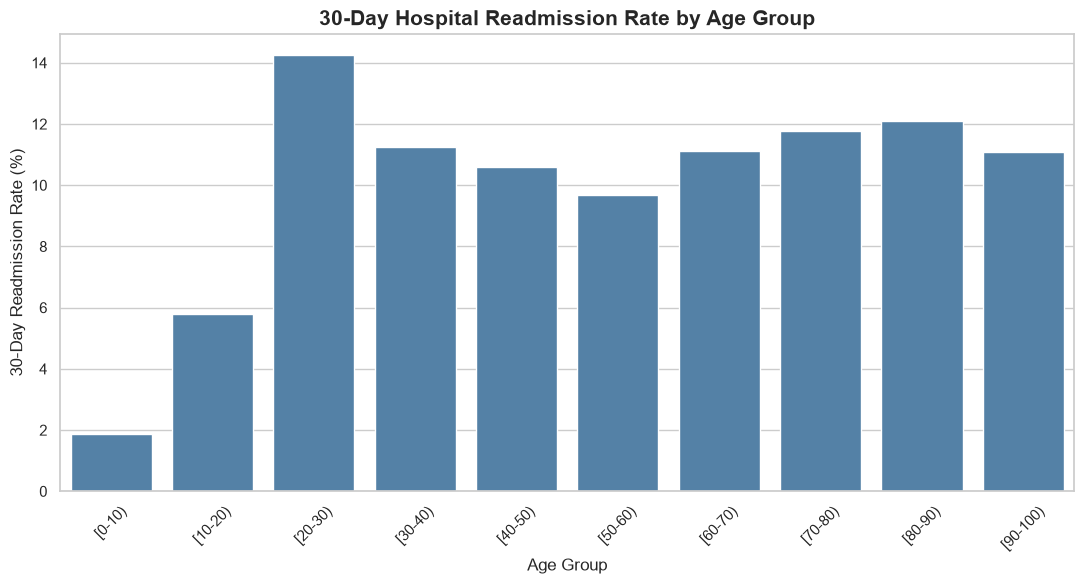

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(11, 6))

sns.barplot(
    data=age_readmission,
    x="age",
    y="readmission_rate",
    color="steelblue"
)

plt.title(
    "30-Day Hospital Readmission Rate by Age Group",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Age Group")
plt.ylabel("30-Day Readmission Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    "../figures/readmission_by_age.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [14]:
from math import sqrt

def wilson_ci(successes, total, z=1.96):
    """Calculate Wilson 95% confidence interval for a proportion."""
    if total == 0:
        return (float("nan"), float("nan"))

    p = successes / total
    denominator = 1 + z**2 / total

    center = (p + z**2 / (2 * total)) / denominator
    margin = (
        z * sqrt(
            p * (1 - p) / total
            + z**2 / (4 * total**2)
        ) / denominator
    )

    return (
        (center - margin) / 1 * 100,
        (center + margin) / 1 * 100
    )

age_readmission[["ci_lower", "ci_upper"]] = (
    age_readmission.apply(
        lambda row: pd.Series(
            wilson_ci(
                row["readmissions_30d"],
                row["total_encounters"]
            )
        ),
        axis=1
    )
)

age_readmission.round(2)

,age,total_encounters,readmissions_30d,readmission_rate,ci_lower,ci_upper
0,[0-10),161,3,1.86,0.64,5.33
1,[10-20),691,40,5.79,4.28,7.79
2,[20-30),1657,236,14.24,12.64,16.01
3,[30-40),3775,424,11.23,10.26,12.28
4,[40-50),9685,1027,10.60,10.01,11.23
5,[50-60),17256,1668,9.67,9.23,10.12
6,[60-70),22483,2502,11.13,10.72,11.55
7,[70-80),26068,3069,11.77,11.39,12.17
8,[80-90),17197,2078,12.08,11.60,12.58
9,[90-100),2793,310,11.10,9.99,12.32


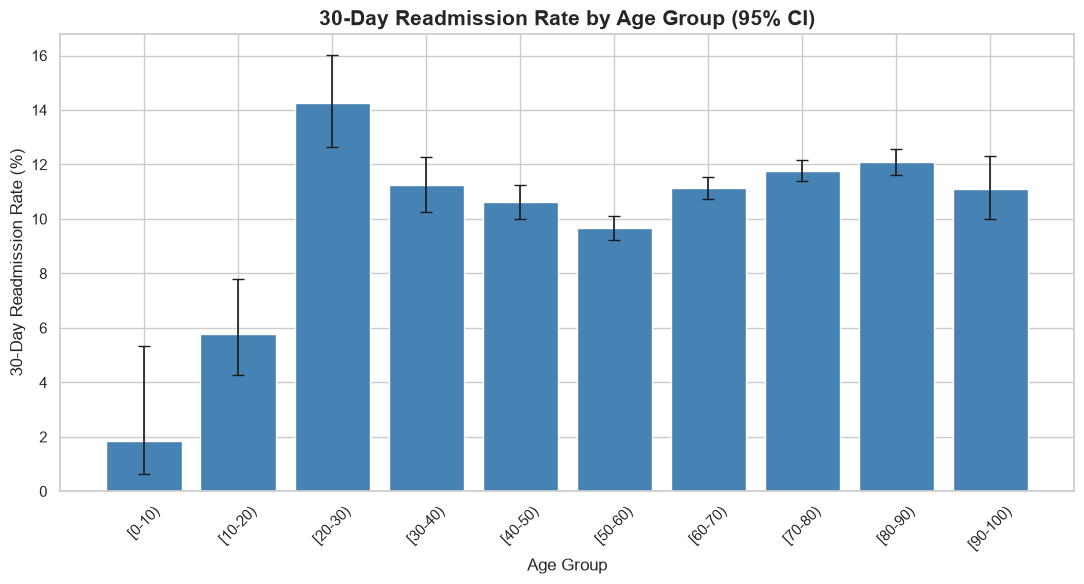

In [15]:
import numpy as np
import matplotlib.pyplot as plt

lower_error = (
    age_readmission["readmission_rate"]
    - age_readmission["ci_lower"]
)

upper_error = (
    age_readmission["ci_upper"]
    - age_readmission["readmission_rate"]
)

errors = np.array([lower_error, upper_error])

plt.figure(figsize=(11, 6))

plt.bar(
    age_readmission["age"],
    age_readmission["readmission_rate"],
    color="steelblue",
    yerr=errors,
    capsize=4,
    error_kw={"elinewidth": 1.2}
)

plt.title(
    "30-Day Readmission Rate by Age Group (95% CI)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Age Group")
plt.ylabel("30-Day Readmission Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../figures/readmission_by_age_ci.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
los_readmission = (
    df_clean.groupby("time_in_hospital")
    .agg(
        total_encounters=("readmitted_30d", "size"),
        readmissions_30d=("readmitted_30d", "sum"),
        readmission_rate=("readmitted_30d", "mean")
    )
    .reset_index()
)

los_readmission["readmission_rate"] *= 100

los_readmission.round(2)

,time_in_hospital,total_encounters,readmissions_30d,readmission_rate
0,1,14208,1162,8.18
1,2,17224,1712,9.94
2,3,17756,1894,10.67
3,4,13924,1644,11.81
4,5,9966,1199,12.03
5,6,7539,949,12.59
6,7,5859,752,12.83
7,8,4391,625,14.23
8,9,3002,412,13.72
9,10,2342,336,14.35


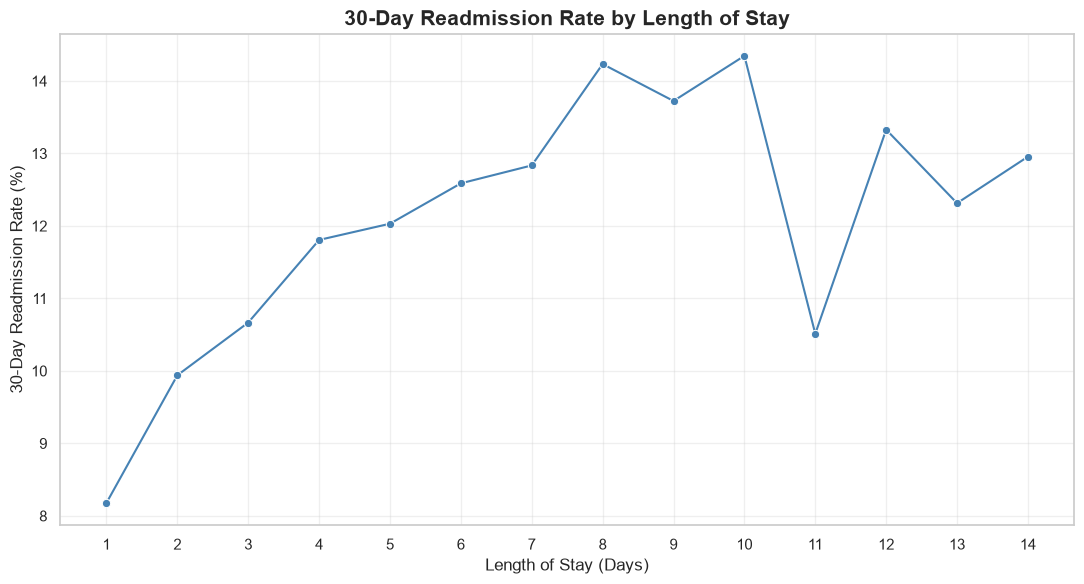

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=los_readmission,
    x="time_in_hospital",
    y="readmission_rate",
    marker="o",
    color="steelblue"
)

plt.title(
    "30-Day Readmission Rate by Length of Stay",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Length of Stay (Days)")
plt.ylabel("30-Day Readmission Rate (%)")

plt.xticks(range(1, 15))
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../figures/readmission_by_los.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
los_readmission[["ci_lower", "ci_upper"]] = (
    los_readmission.apply(
        lambda row: pd.Series(
            wilson_ci(
                row["readmissions_30d"],
                row["total_encounters"]
            )
        ),
        axis=1
    )
)

los_readmission.round(2)

,time_in_hospital,total_encounters,readmissions_30d,readmission_rate,ci_lower,ci_upper
0,1,14208,1162,8.18,7.74,8.64
1,2,17224,1712,9.94,9.50,10.40
2,3,17756,1894,10.67,10.22,11.13
3,4,13924,1644,11.81,11.28,12.35
4,5,9966,1199,12.03,11.41,12.68
5,6,7539,949,12.59,11.86,13.36
6,7,5859,752,12.83,12.00,13.72
7,8,4391,625,14.23,13.23,15.30
8,9,3002,412,13.72,12.54,15.00
9,10,2342,336,14.35,12.99,15.82


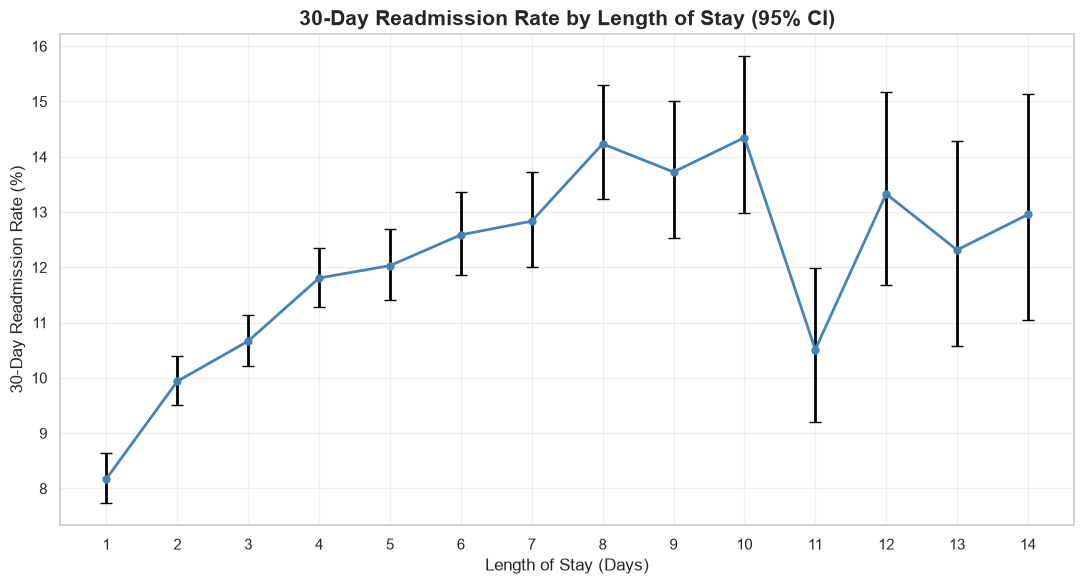

In [19]:
plt.figure(figsize=(11, 6))

plt.errorbar(
    los_readmission["time_in_hospital"],
    los_readmission["readmission_rate"],
    yerr=[
        los_readmission["readmission_rate"] - los_readmission["ci_lower"],
        los_readmission["ci_upper"] - los_readmission["readmission_rate"]
    ],
    fmt="o-",
    capsize=4,
    color="steelblue",
    ecolor="black",
    linewidth=2,
    markersize=5
)

plt.title(
    "30-Day Readmission Rate by Length of Stay (95% CI)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Length of Stay (Days)")
plt.ylabel("30-Day Readmission Rate (%)")
plt.xticks(range(1, 15))
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../figures/readmission_by_los_ci.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
gender_readmission = (
    df_clean.groupby("gender")
    .agg(
        total_encounters=("readmitted_30d", "size"),
        readmissions_30d=("readmitted_30d", "sum"),
        readmission_rate=("readmitted_30d", "mean")
    )
    .reset_index()
)

gender_readmission["readmission_rate"] *= 100
gender_readmission.round(2)

,gender,total_encounters,readmissions_30d,readmission_rate
0,Female,54708,6152,11.25
1,Male,47055,5205,11.06
2,Unknown/Invalid,3,0,0.00


In [21]:
gender_readmission[["ci_lower", "ci_upper"]] = (
    gender_readmission.apply(
        lambda row: pd.Series(
            wilson_ci(
                row["readmissions_30d"],
                row["total_encounters"]
            )
        ),
        axis=1
    )
)

gender_readmission.round(2)

,gender,total_encounters,readmissions_30d,readmission_rate,ci_lower,ci_upper
0,Female,54708,6152,11.25,10.98,11.51
1,Male,47055,5205,11.06,10.78,11.35
2,Unknown/Invalid,3,0,0.00,0.00,56.15


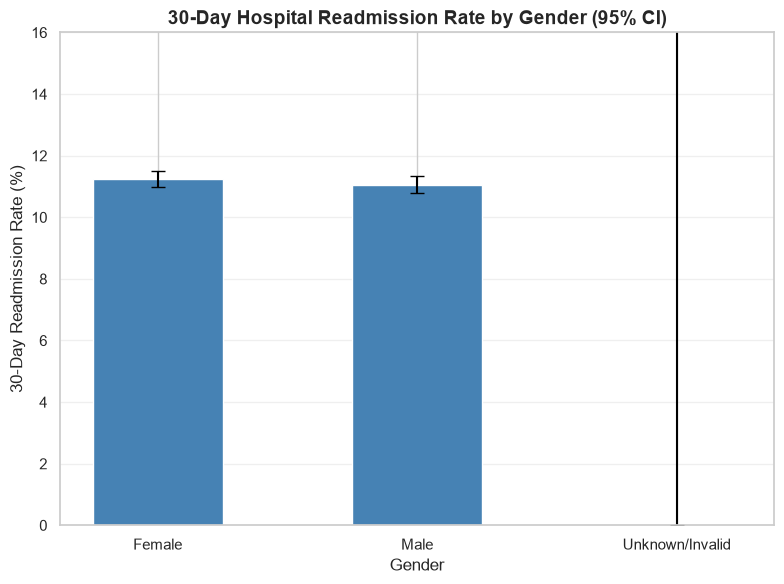

In [22]:
plt.figure(figsize=(8, 6))

plt.bar(
    gender_readmission["gender"],
    gender_readmission["readmission_rate"],
    color="steelblue",
    width=0.5
)

plt.errorbar(
    gender_readmission["gender"],
    gender_readmission["readmission_rate"],
    yerr=[
        gender_readmission["readmission_rate"] - gender_readmission["ci_lower"],
        gender_readmission["ci_upper"] - gender_readmission["readmission_rate"]
    ],
    fmt="none",
    ecolor="black",
    capsize=5
)

plt.title(
    "30-Day Hospital Readmission Rate by Gender (95% CI)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Gender")
plt.ylabel("30-Day Readmission Rate (%)")
plt.ylim(0, 16)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../figures/readmission_by_gender_ci.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
gender_plot = gender_readmission[
    gender_readmission["gender"].isin(["Female", "Male"])
].copy()

gender_plot.round(2)

,gender,total_encounters,readmissions_30d,readmission_rate,ci_lower,ci_upper
0,Female,54708,6152,11.25,10.98,11.51
1,Male,47055,5205,11.06,10.78,11.35


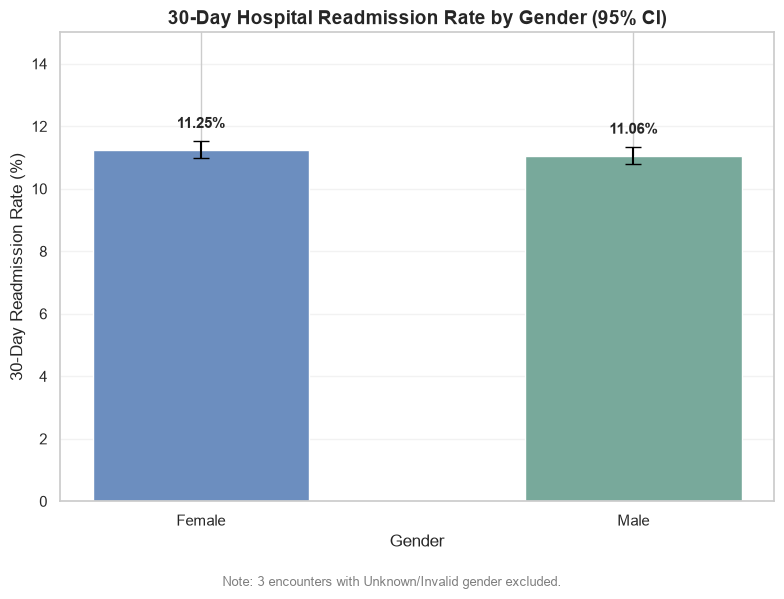

In [24]:
plt.figure(figsize=(8, 6))

plt.bar(
    gender_plot["gender"],
    gender_plot["readmission_rate"],
    color=["#6C8EBF", "#78A99B"],
    width=0.5
)

plt.errorbar(
    gender_plot["gender"],
    gender_plot["readmission_rate"],
    yerr=[
        gender_plot["readmission_rate"] - gender_plot["ci_lower"],
        gender_plot["ci_upper"] - gender_plot["readmission_rate"]
    ],
    fmt="none",
    ecolor="black",
    capsize=6,
    linewidth=1.5
)

for i, row in gender_plot.reset_index(drop=True).iterrows():
    plt.text(
        i,
        row["readmission_rate"] + 0.7,
        f'{row["readmission_rate"]:.2f}%',
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "30-Day Hospital Readmission Rate by Gender (95% CI)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Gender")
plt.ylabel("30-Day Readmission Rate (%)")
plt.ylim(0, 15)
plt.grid(axis="y", alpha=0.25)

plt.figtext(
    0.5, 0.01,
    "Note: 3 encounters with Unknown/Invalid gender excluded.",
    ha="center",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

plt.savefig(
    "../figures/readmission_by_gender_ci.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
medication_readmission = (
    df_clean.groupby("diabetesMed")
    .agg(
        total_encounters=("readmitted_30d", "size"),
        readmissions_30d=("readmitted_30d", "sum"),
        readmission_rate=("readmitted_30d", "mean")
    )
    .reset_index()
)

medication_readmission["readmission_rate"] *= 100

medication_readmission.round(2)

,diabetesMed,total_encounters,readmissions_30d,readmission_rate
0,No,23403,2246,9.60
1,Yes,78363,9111,11.63


In [27]:
medication_readmission[["ci_lower", "ci_upper"]] = (
    medication_readmission.apply(
        lambda row: pd.Series(
            wilson_ci(
                row["readmissions_30d"],
                row["total_encounters"]
            )
        ),
        axis=1
    )
)

medication_readmission.round(2)

,diabetesMed,total_encounters,readmissions_30d,readmission_rate,ci_lower,ci_upper
0,No,23403,2246,9.60,9.23,9.98
1,Yes,78363,9111,11.63,11.40,11.85


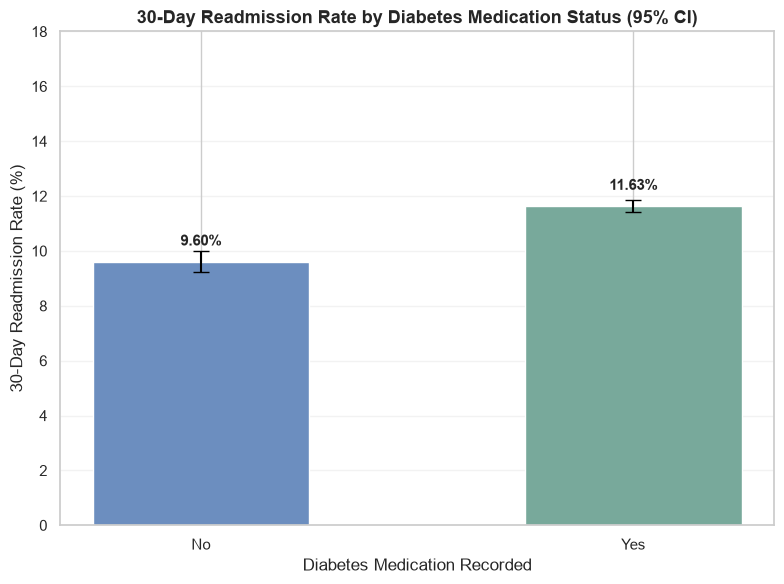

In [28]:
plt.figure(figsize=(8, 6))

plt.bar(
    medication_readmission["diabetesMed"],
    medication_readmission["readmission_rate"],
    color=["#6C8EBF", "#78A99B"],
    width=0.5
)

plt.errorbar(
    medication_readmission["diabetesMed"],
    medication_readmission["readmission_rate"],
    yerr=[
        medication_readmission["readmission_rate"] - medication_readmission["ci_lower"],
        medication_readmission["ci_upper"] - medication_readmission["readmission_rate"]
    ],
    fmt="none",
    ecolor="black",
    capsize=6,
    linewidth=1.5
)

for i, row in medication_readmission.reset_index(drop=True).iterrows():
    plt.text(
        i,
        row["readmission_rate"] + 0.6,
        f'{row["readmission_rate"]:.2f}%',
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "30-Day Readmission Rate by Diabetes Medication Status (95% CI)",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Diabetes Medication Recorded")
plt.ylabel("30-Day Readmission Rate (%)")
plt.ylim(0, 18)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    "../figures/readmission_by_medication_ci.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
from pathlib import Path

output_path = Path("../data/processed/diabetes_cleaned.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(output_path, index=False)

print(f"Saved cleaned dataset to: {output_path}")
print(f"Dataset shape: {df_clean.shape}")
print(f"File size: {output_path.stat().st_size / (1024**2):.2f} MB")

Saved cleaned dataset to: ../data/processed/diabetes_cleaned.csv
Dataset shape: (101766, 50)
File size: 17.37 MB


In [31]:
df_verify = pd.read_csv(
    output_path,
    dtype={"payer_code": "string"}
)

assert df_verify.shape == df_clean.shape
assert df_verify["readmitted_30d"].isin([0, 1]).all()
assert df_verify["readmitted_30d"].sum() == 11357

print("Processed dataset validation passed!")

Processed dataset validation passed!
